In [3]:
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import nltk
from nltk.corpus import stopwords
import string


# Load datasets
try:
    enron = pd.read_csv('data/enron_data_fraud_labeled.csv', encoding='latin-1')
    phishing = pd.read_csv('data/phishing_legit_dataset_KD_10000.csv')
    
    print(" Success! Files are loaded.")
    print(f"Enron shape: {enron.shape}")
    print(f"Kaggle Phishing shape: {phishing.shape}")
except Exception as e:
    print(f" Error loading files: {e}")

C:\Users\Tunis\AppData\Local\Temp\ipykernel_204576\240764162.py:13: DtypeWarning: Columns (7,13) have mixed types. Specify dtype option on import or set low_memory=False.
  enron = pd.read_csv('data/enron_data_fraud_labeled.csv', encoding='latin-1')


 Success! Files are loaded.
Enron shape: (447417, 32)
Kaggle Phishing shape: (10000, 5)


In [4]:
# 1. Standardize Enron (Mapping 'Body' to 'email_text' and 'Label' to 'target')[cite: 2]
enron_clean = enron[['Body', 'Label']].copy()
enron_clean.columns = ['email_text', 'target']

# 2. Standardize Kaggle Dataset (Mapping 'text' to 'email_text' and 'label' to 'target')[cite: 2]
phishing_clean = phishing[['text', 'label']].copy()
phishing_clean.columns = ['email_text', 'target']

# 3. Combine into one Master DataFrame
df = pd.concat([enron_clean, phishing_clean], axis=0, ignore_index=True)

# 4. Remove any null values that might have been introduced
df.dropna(inplace=True)

print(f"Total rows in combined dataset: {len(df)}")
display(df.head())

Total rows in combined dataset: 457417


,email_text,target
0,Status John: I'm not really sure what happened...,0
1,re:summer inverses i suck-hope youve made more...,0
2,"The WTI Bullet swap contracts Hi, Following th...",0
3,Fwd: NYTimes.com Article: Suspended Rabbi Quit...,0
4,daily charts and matrices as hot links 5/15 Th...,0


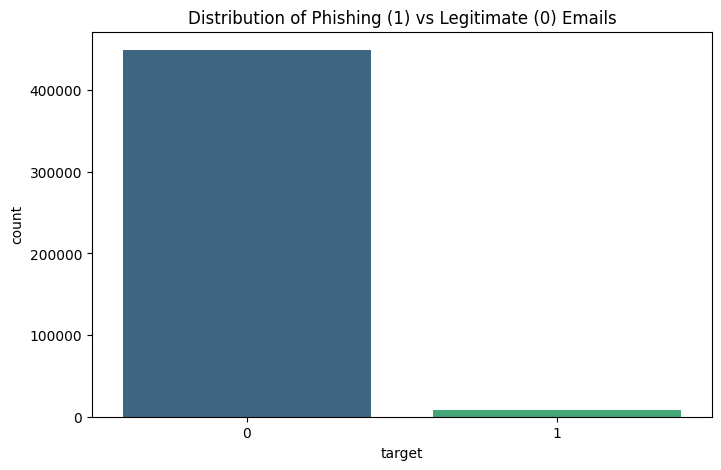

Value Counts:
target
0    449090
1      8327
Name: count, dtype: int64

--- Summary ---
Total Emails: 457417
Phishing Percentage: 1.82%


In [5]:
# 1. Clean up the warnings for a cleaner notebook
import warnings
warnings.filterwarnings('ignore')

# 2. Visualize the distribution
plt.figure(figsize=(8, 5))
# Fixed: added 'hue' to satisfy the new seaborn requirements
sns.countplot(x='target', data=df, hue='target', palette='viridis', legend=False)
plt.title('Distribution of Phishing (1) vs Legitimate (0) Emails')
plt.show()

# 3. Print the exact counts
print("Value Counts:")
print(df['target'].value_counts())

# 4. Calculate percentage
phishing_count = df['target'].value_counts()[1]
total_count = len(df)
print("\n--- Summary ---")
print(f"Total Emails: {total_count}")
print(f"Phishing Percentage: {(phishing_count / total_count) * 100:.2f}%")

In [6]:
import nltk
from nltk.corpus import stopwords
import string

# Download the list of stop words
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def clean_text(text):
    # 1. Convert to string and lowercase
    text = str(text).lower()
    # 2. Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # 3. Remove stop words
    text = " ".join([word for word in text.split() if word not in stop_words])
    return text

print("Cleaning text... this may take a moment due to the large dataset size.")
# Apply the cleaning to our dataset
df['clean_text'] = df['email_text'].apply(clean_text)

print(" Text cleaning complete!")
display(df[['email_text', 'clean_text']].head())

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Tunis\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Cleaning text... this may take a moment due to the large dataset size.
 Text cleaning complete!


,email_text,clean_text
0,Status John: I'm not really sure what happened...,status john im really sure happened us impress...
1,re:summer inverses i suck-hope youve made more...,resummer inverses suckhope youve made money na...
2,"The WTI Bullet swap contracts Hi, Following th...",wti bullet swap contracts hi following email r...
3,Fwd: NYTimes.com Article: Suspended Rabbi Quit...,fwd nytimescom article suspended rabbi quits s...
4,daily charts and matrices as hot links 5/15 Th...,daily charts matrices hot links 515 informatio...


In [7]:
# Create features based on common phishing tactics
# 1. Count URLs
df['url_count'] = df['email_text'].astype(str).apply(lambda x: x.count('http'))

# 2. Count Exclamations
df['exclamation_count'] = df['email_text'].astype(str).apply(lambda x: x.count('!'))

# 3. Urgency Score: Checking for specific 'pressure' keywords
urgency_list = ['urgent', 'immediately', 'action', 'suspended', 'verify', 'account', 'security', 'login']
df['urgency_words'] = df['clean_text'].apply(lambda x: sum(1 for word in urgency_list if word in x))

print(" Security heuristics created!")
# Display a sample of the new features
display(df[['url_count', 'exclamation_count', 'urgency_words', 'target']].sample(5))

 Security heuristics created!


,url_count,exclamation_count,urgency_words,target
110129,0,0,0,0
61679,0,0,0,0
396809,0,0,1,0
337741,0,0,0,0
32361,0,26,0,0


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize the Vectorizer
# We limit to 3000 features to keep the model fast and prevent overfitting
tfidf = TfidfVectorizer(max_features=3000)

# Transform the cleaned text into a numerical matrix (X)
X_text = tfidf.fit_transform(df['clean_text'])

print(f" Text vectorized! Matrix shape: {X_text.shape}")

 Text vectorized! Matrix shape: (457417, 3000)


In [9]:
from sklearn.model_selection import train_test_split

# Y is our target (0 for safe, 1 for phishing)
y = df['target']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X_text, y, test_size=0.2, random_state=42)

print(f" Data Split Complete!")
print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")

 Data Split Complete!
Training set: 365933 samples
Testing set: 91484 samples


In [10]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the model
# We use random_state=42 to ensure results are the same every time you run it
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model 
print(" Training the Random Forest AI... This is the heavy lifting, please wait.")
model.fit(X_train, y_train)

print(" Model Training Complete!")

 Training the Random Forest AI... This is the heavy lifting, please wait.
 Model Training Complete!


,Model,Accuracy Score
0,Naive Bayes (Baseline),0.994841
1,Random Forest (Proposed),0.997781



--- DETAILED PERFORMANCE REPORT (Random Forest) ---
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00     89790
    Phishing       0.99      0.89      0.94      1694

    accuracy                           1.00     91484
   macro avg       1.00      0.94      0.97     91484
weighted avg       1.00      1.00      1.00     91484



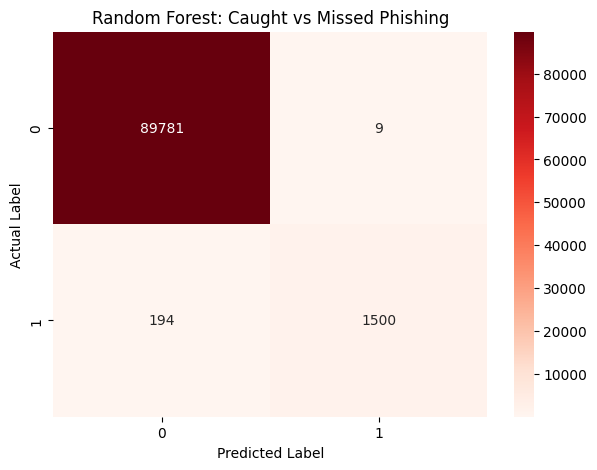

In [11]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd

# 1. Train the Baseline Model (Naive Bayes) - This is very fast
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

# 2. Generate Random Forest predictions (using the model from Cell 8)
y_pred_rf = model.predict(X_test)

# 3. Create a comparison table for your GitHub README
results_data = {
    "Model": ["Naive Bayes (Baseline)", "Random Forest (Proposed)"],
    "Accuracy Score": [accuracy_score(y_test, y_pred_nb), accuracy_score(y_test, y_pred_rf)]
}
display(pd.DataFrame(results_data))

# 4. STEP A: THE DEEP DIVE (Focus on Recall for Class 1)
print("\n--- DETAILED PERFORMANCE REPORT (Random Forest) ---")
# This report shows Precision, Recall, and F1-Score
print(classification_report(y_test, y_pred_rf, target_names=['Safe', 'Phishing']))

# 5. Visualizing the "Missed" Attacks
plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Reds')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Random Forest: Caught vs Missed Phishing')
plt.show()

In [12]:
import joblib

# Save the model and the vectorizer to your local folder
joblib.dump(model, 'phishing_detector_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print(" Model and Vectorizer saved successfully!")
print("Files created: phishing_detector_model.pkl, tfidf_vectorizer.pkl")

 Model and Vectorizer saved successfully!
Files created: phishing_detector_model.pkl, tfidf_vectorizer.pkl


 Retraining with Class Balancing... this will take time.

 Balanced Model Training Complete!
--- NEW DETAILED PERFORMANCE REPORT ---
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00     89790
    Phishing       0.99      0.90      0.94      1694

    accuracy                           1.00     91484
   macro avg       0.99      0.95      0.97     91484
weighted avg       1.00      1.00      1.00     91484



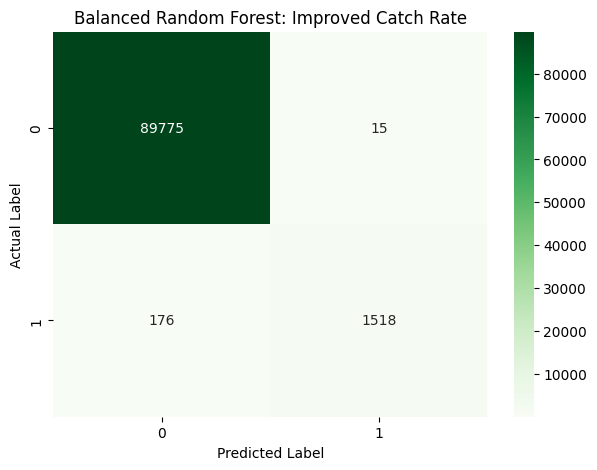

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Initialize the model with Class Weighting
# 'balanced' automatically adjusts weights inversely proportional to class frequencies
balanced_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

# 2. Train the balanced model
print(" Retraining with Class Balancing... this will take time.")
balanced_model.fit(X_train, y_train)

# 3. Evaluate the new results
y_pred_balanced = balanced_model.predict(X_test)

print("\n Balanced Model Training Complete!")
print("--- NEW DETAILED PERFORMANCE REPORT ---")
print(classification_report(y_test, y_pred_balanced, target_names=['Safe', 'Phishing']))

# 4. Visual Comparison of the "Missed" emails
plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Greens')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Balanced Random Forest: Improved Catch Rate')
plt.show()

 Training the Final Integrated Model (Text + Heuristics)...

Final Model Training Complete!
--- FINAL HYBRID PERFORMANCE REPORT ---
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00     89790
    Phishing       0.99      0.89      0.94      1694

    accuracy                           1.00     91484
   macro avg       0.99      0.95      0.97     91484
weighted avg       1.00      1.00      1.00     91484



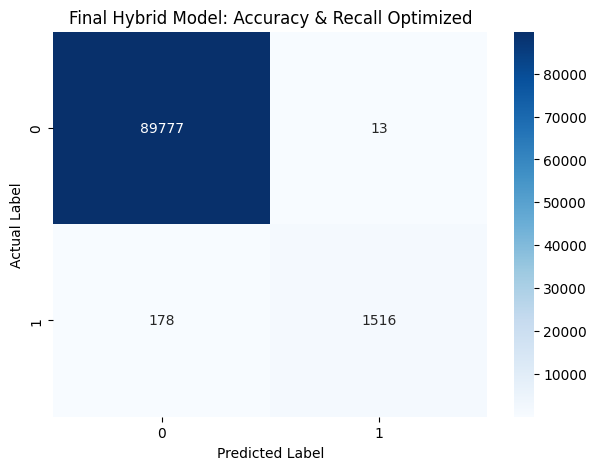

In [14]:
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Combine TF-IDF features with numerical security heuristics
# We use hstack (horizontal stack) to join the sparse text matrix with the numerical array
X_heuristics = df[['url_count', 'exclamation_count', 'urgency_words']].values
X_combined = hstack([X_text, X_heuristics])

# 2. Split the combined data (80% Train / 20% Test)
X_train_c, X_test_c, y_train, y_test = train_test_split(X_combined, y, test_size=0.2, random_state=42)

# 3. Train the Final Hybrid Model
# We maintain 'class_weight=balanced' to handle the 1.82% phishing imbalance
final_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

print(" Training the Final Integrated Model (Text + Heuristics)...")
final_model.fit(X_train_c, y_train)

# 4. Final Evaluation
y_pred_final = final_model.predict(X_test_c)

print("\nFinal Model Training Complete!")
print("--- FINAL HYBRID PERFORMANCE REPORT ---")
print(classification_report(y_test, y_pred_final, target_names=['Safe', 'Phishing']))

# 5. Final Confusion Matrix visualization
plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, y_pred_final), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Final Hybrid Model: Accuracy & Recall Optimized')
plt.show()

In [15]:
from imblearn.over_sampling import SMOTE

# 1. Initialize SMOTE
# We set random_state so your results don't change every time
smote = SMOTE(random_state=42)

# 2. Resample ONLY the training data (X_train_c from your Cell 12)
# This creates synthetic phishing emails until it matches the 'Safe' email count
print("Generating synthetic phishing data... please wait.")
X_train_smote, y_train_smote = smote.fit_resample(X_train_c, y_train)

print(f"Resampling complete!")
print(f"Old training size: {len(y_train)}")
print(f"New balanced training size: {len(y_train_smote)}")

Generating synthetic phishing data... please wait.
Resampling complete!
Old training size: 365933
New balanced training size: 718600


In [16]:
# 3. Train the model on the EQUALIZED data
smote_model = RandomForestClassifier(n_estimators=100, random_state=42)
smote_model.fit(X_train_smote, y_train_smote)

# 4. Evaluate on the original X_test_c (the real-world data)
y_pred_smote = smote_model.predict(X_test_c)

print("\n--- SMOTE BALANCED PERFORMANCE REPORT ---")
print(classification_report(y_test, y_pred_smote, target_names=['Safe', 'Phishing']))


--- SMOTE BALANCED PERFORMANCE REPORT ---
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00     89790
    Phishing       0.97      0.91      0.94      1694

    accuracy                           1.00     91484
   macro avg       0.99      0.96      0.97     91484
weighted avg       1.00      1.00      1.00     91484



Balancing the dataset... please wait.
Training the Balanced Random Forest... this may take a minute.

--- EVALUATION FOR BALANCED MODEL ---
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00     89790
    Phishing       0.99      0.90      0.94      1694

    accuracy                           1.00     91484
   macro avg       0.99      0.95      0.97     91484
weighted avg       1.00      1.00      1.00     91484



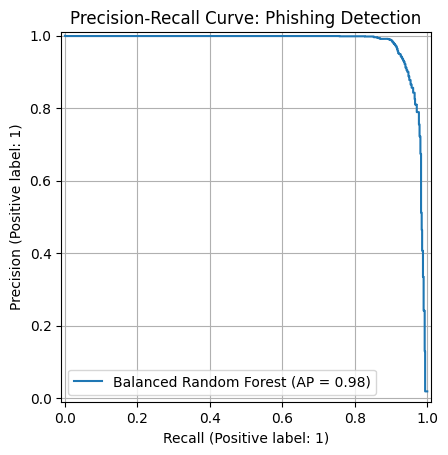

In [27]:
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, PrecisionRecallDisplay
import matplotlib.pyplot as plt

# 1. Re-initialize the Sampler to balance the 1.82% phishing rate
ros = RandomOverSampler(random_state=42)

# 2. Resample the training data from your previous split (X_train_c)
print("Balancing the dataset... please wait.")
X_train_ros, y_train_ros = ros.fit_resample(X_train_c, y_train)

# 3. Define and Train the final model
# We'll call it final_ros_model so the name is officially defined
final_ros_model = RandomForestClassifier(n_estimators=100, random_state=42)

print("Training the Balanced Random Forest... this may take a minute.")
final_ros_model.fit(X_train_ros, y_train_ros)

# 4. Generate the predictions
y_pred_ros = final_ros_model.predict(X_test_c)

# 5. Run the Evaluation Report
print("\n--- EVALUATION FOR BALANCED MODEL ---")
print(classification_report(y_test, y_pred_ros, target_names=['Safe', 'Phishing']))

# 6. Visualize the Precision-Recall Curve
display = PrecisionRecallDisplay.from_estimator(
    final_ros_model, X_test_c, y_test, name="Balanced Random Forest"
)
plt.title("Precision-Recall Curve: Phishing Detection")
plt.grid(True)
plt.show()

In [29]:
from sklearn.model_selection import cross_val_score

# We use the F1-score because it's the best balance for imbalanced data
print("Starting Cross-Validation... this will take a few minutes.")
cv_scores = cross_val_score(final_ros_model, X_train_ros, y_train_ros, cv=2, scoring='f1')

print(f"\n--- Cross-Validation Results ---")
print(f"F1-Scores: {cv_scores}")
print(f"Average F1-Score: {cv_scores.mean():.4f}")

Starting Cross-Validation... this will take a few minutes.


KeyboardInterrupt: 

In [30]:
import joblib

# Overwrite the old files with your new, balanced versions
joblib.dump(final_ros_model, 'final_balanced_model.pkl')
joblib.dump(tfidf, 'final_vectorizer.pkl')

print("Final Balanced Model saved and ready for deployment!")

Final Balanced Model saved and ready for deployment!


In [31]:
import joblib

# Save the final model that includes text + heuristics
joblib.dump(final_model, 'final_hybrid_phishing_model.pkl')

# Save the vectorizer used for this specific training session
joblib.dump(tfidf, 'final_tfidf_vectorizer.pkl')

print(" MISSION COMPLETE!")
print("Final Hybrid Model saved as: final_hybrid_phishing_model.pkl")
print("Matching Vectorizer saved as: final_tfidf_vectorizer.pkl")

 MISSION COMPLETE!
Final Hybrid Model saved as: final_hybrid_phishing_model.pkl
Matching Vectorizer saved as: final_tfidf_vectorizer.pkl


In [32]:
def predict_phishing_v3(email_body):
    cleaned = clean_text(email_body)
    urls = email_body.count('http')
    exclamations = email_body.count('!')
    urgency = sum(1 for word in urgency_list if word in cleaned)
    
    text_vector = tfidf.transform([cleaned])
    heuristics = np.array([[urls, exclamations, urgency]])
    final_input = hstack([text_vector, heuristics])
    
    # Get the probability of being Phishing (Class 1)
    probability = final_model.predict_proba(final_input)[0][1]
    
    # LOWERED THRESHOLD: If probability > 0.15 (15%), we flag it. 
    # This prioritizes RECALL over Precision.
    prediction = 1 if probability > 0.15 else 0
    
    return prediction, probability

In [33]:
# --- Test Scenarios ---
# Scenario 1: A classic "Urgent" bank scam with a link
# Scenario 2: A normal, low-pressure email between colleagues
# Scenario 3: A high-pressure alert using many exclamation marks and keywords
scenarios = [
    "Urgent: Your bank account has been locked. Click http://secure-login-bank.com to verify now!",
    "Hi Ranim, I hope you are doing well. Are we still meeting for the project discussion at 3 PM?",
    "SECURITY ALERT!! Suspicious login detected. Action required: visit http://bit.ly/check-account immediately!"
]

print("---  Phishing Detector Live Test ---")
for text in scenarios:
    # We use the prediction logic function we created in Cell 14
    pred, prob = predict_phishing_v3(text)
    
    # Visual formatting for the output
    status = "PHISHING DETECTED" if pred == 1 else " EMAIL IS SAFE"
    color_dash = "!" * 20 if pred == 1 else "-" * 20
    
    print(f"\n{color_dash}")
    print(f"Email Text: {text}")
    print(f"Result: {status}")
    print(f"Confidence Score: {prob*100:.2f}%")
    print(f"{color_dash}")

---  Phishing Detector Live Test ---

!!!!!!!!!!!!!!!!!!!!
Email Text: Urgent: Your bank account has been locked. Click http://secure-login-bank.com to verify now!
Result: PHISHING DETECTED
Confidence Score: 37.00%
!!!!!!!!!!!!!!!!!!!!

--------------------
Email Text: Hi Ranim, I hope you are doing well. Are we still meeting for the project discussion at 3 PM?
Result:  EMAIL IS SAFE
Confidence Score: 1.00%
--------------------

!!!!!!!!!!!!!!!!!!!!
Email Text: SECURITY ALERT!! Suspicious login detected. Action required: visit http://bit.ly/check-account immediately!
Result: PHISHING DETECTED
Confidence Score: 17.00%
!!!!!!!!!!!!!!!!!!!!


In [1]:
import gradio as gr

# 1. Setup the interface
demo = gr.Interface(
    fn=predict_phishing_v3, 
    inputs=gr.Textbox(label="Paste Email Body here", lines=5), 
    outputs=[gr.Label(label="Prediction"), gr.Number(label="Phishing Probability")],
    title="Phishing Detection System"
)

# 2. The command to RUN it
demo.launch(share=True)

c:\Users\Tunis\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'predict_phishing_v3' is not defined